In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

In [3]:
class DecisionTree:
    def __init__(self,max_depth = 10,min_split = 2):
        self.max_depth = max_depth
        self.min_split = min_split #min number of points to split a node or max leaf size

    def fit(self,X,y):
        self.labels = np.unique(y)
        self.root = self.constructTree(X,y,0)

    def predict(self,X):
        ypred = []
        for i in range(len(X)):
            p = self.predict1(X[i],self.root)
            lb = self.labels[np.argmax(p)]
            ypred.append(lb)

        return np.array(ypred)

    def predict1(self,t,node):
        if node['isLeaf'] == True:
            return node['prediction']
        elif t[node['Feature']] < node['Threshold']:
            return self.predict1(t,node['Left'])
        else:
            return self.predict1(t,node['Right'])
            

    def constructTree(self,X,y,curDepth=0):
        if len(X) == 0 or curDepth > self.max_depth:
            return None
        
        if len(X) >= self.min_split:
            parentEntropy = self.entropy(y)
            weightedChildEntropy = []
            for feat in range(X.shape[1]):
                th = X[:,feat].mean() #threshold using mean of features
                wce = 0
                #child 1
                wce += np.mean(X[:,feat] < th)*self.entropy(y[X[:,feat]<th]) # np.mean(weight if true for smaller values) x entropy calculated by giving y
                #child 2
                wce += np.mean(X[:,feat] >= th)*self.entropy(y[X[:,feat]>=th]) #np.mean(weight if true for larger values)
                weightedChildEntropy.append(wce) 

            InformationGain = parentEntropy-np.array(weightedChildEntropy) #info gain of each point
            feat = np.argmax(InformationGain) #choosing info gain with max value
            th = X[:,feat].mean()

            node = {
                "Feature" : feat,
                "Threshold" : th,
                "Left" : None,
                "Right" : None,
                "isLeaf" : False
            }

            LSpx,RSpx = X[X[:,feat] < th], X[X[:,feat] >= th] #left split and right split of x where left is smaller and right is greater than threshold
            LSpy,RSpy = y[X[:,feat] < th], y[X[:,feat] >= th] ##left split and right split of y

            node['Left'] = self.constructTree(LSpx,LSpy,curDepth+1) #creating tree and adding +1 to depth for next level/height/depth
            node['Right'] = self.constructTree(RSpx,RSpy,curDepth+1)

            if node['Left'] == None or node['Right'] == None:
                node['isLeaf'] = True

            if node['isLeaf'] == True:
                node['prediction'] = self.predictions(y) #calculating probability of classes
                
            return node
        
        else:
            node = {
                "Feature" : None,
                "Threshold" : None,
                "Left" : None,
                "Right" : None,
                "isLeaf" : True,
                'prediction' : self.predictions(y)
            }
            
            return node
            
    def predictions(self,y):
        prob = np.zeros_like(self.labels,dtype='float32')
        for i in range(prob.shape[0]):
            prob[i] = (y == self.labels[i]).mean()

        return prob
            

    def entropy(self,y):
        values,counts = np.unique(y,return_counts=True)
        prob = counts/len(y)
        return -np.sum(prob*np.log2(prob))

In [47]:
data = pd.read_csv('./Titanic.csv')

In [5]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [48]:
cols_drop = ['PassengerId', 'Name', 'Ticket', 'Cabin']

In [49]:
data = data.drop(cols_drop, axis = 1)

In [8]:
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [50]:
lab_enc = LabelEncoder()
data['Sex'] = lab_enc.fit_transform(data['Sex'])
data['Embarked'] = lab_enc.fit_transform(data['Embarked'])
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


In [10]:
data.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      0
dtype: int64

In [51]:
data = data.fillna(data['Age'].mean())

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    int64  
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 55.8 KB


In [52]:
input_cols = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
output_col = ['Survived']

X_data = data[input_cols]
Y_data = data['Survived']
X_data.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,22.0,1,0,7.2500,2
1,1,0,38.0,1,0,71.2833,0
2,3,0,26.0,0,0,7.9250,2
3,1,0,35.0,1,0,53.1000,2
4,3,1,35.0,0,0,8.0500,2


In [14]:
print(X_data.shape, Y_data.shape)

(891, 7) (891,)


In [53]:
X_data = X_data.values
Y_data = Y_data.values

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
#Gini (Gini impurity) is a measure of node impurity used to evaluate the quality of a split. It quantifies the probability of a randomly chosen element being incorrectly classified according to the class distribution in a given node
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [54]:
x_train,x_test,y_train,y_test = train_test_split(X_data,Y_data,train_size = 0.8)

In [37]:
#dt = DecisionTree(max_depth=7,min_split=10)
dt = DecisionTreeClassifier(max_depth=3)
# rf = RandomForestClassifier(1000,max_depth=7)
dt.fit(x_train,y_train)
#dt.root()

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [38]:
accuracy_score(y_train,dt.predict(x_train))

0.8202247191011236

In [39]:
accuracy_score(y_test,dt.predict(x_test))

0.7877094972067039

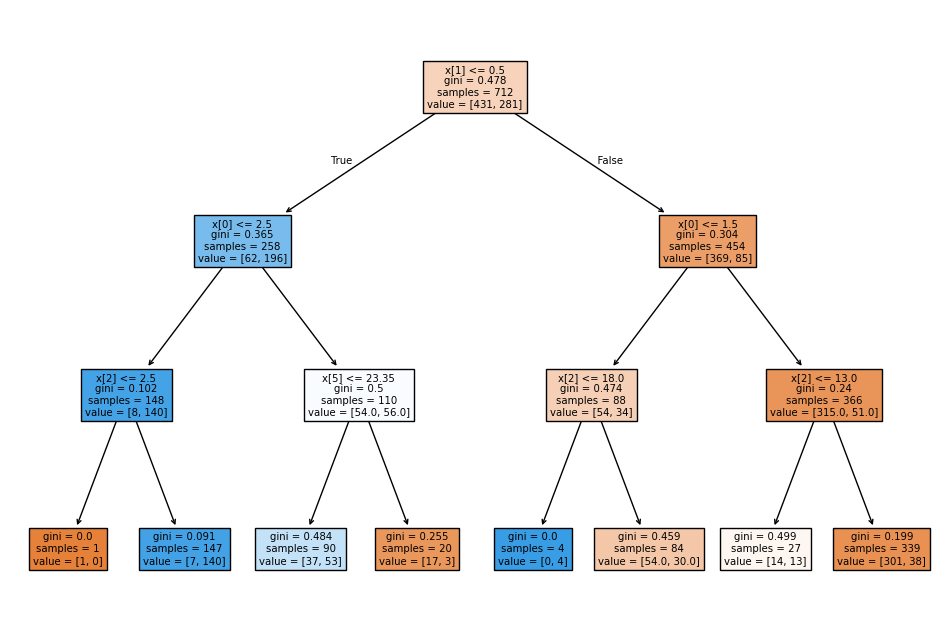

In [41]:
from sklearn import tree
import matplotlib.pyplot as plt
plt.figure(figsize=(12,8))
tree.plot_tree(dt, filled=True)
plt.savefig('tree.jpg')
plt.show()

In [55]:
dt = DecisionTree(max_depth=7,min_split=10)
# dt = DecisionTreeClassifier(max_depth=100)
# rf = RandomForestClassifier(1000,max_depth=7)
dt.fit(x_train,y_train)
dt.root

{'Feature': np.int64(1),
 'Threshold': np.float64(0.6558988764044944),
 'Left': {'Feature': np.int64(0),
  'Threshold': np.float64(2.146938775510204),
  'Left': {'Feature': np.int64(6),
   'Threshold': np.float64(1.455223880597015),
   'Left': {'Feature': np.int64(2),
    'Threshold': np.float64(32.80757918552036),
    'Left': {'Feature': np.int64(0),
     'Threshold': np.float64(1.3478260869565217),
     'Left': {'Feature': np.int64(0),
      'Threshold': np.float64(1.0),
      'Left': None,
      'Right': {'Feature': np.int64(0),
       'Threshold': np.float64(1.0),
       'Left': None,
       'Right': {'Feature': np.int64(0),
        'Threshold': np.float64(1.0),
        'Left': None,
        'Right': None,
        'isLeaf': True,
        'prediction': array([0., 1.], dtype=float32)},
       'isLeaf': True,
       'prediction': array([0., 1.], dtype=float32)},
      'isLeaf': True,
      'prediction': array([0., 1.], dtype=float32)},
     'Right': {'Feature': None,
      'Threshold'

In [56]:
accuracy_score(y_train,dt.predict(x_train))

0.8553370786516854

In [57]:
accuracy_score(y_test,dt.predict(x_test))

0.8491620111731844

In [ ]:
#ENSEMBLE LEARNING 
#RANDOM FOREST OR BAGGING

In [60]:
#dt = DecisionTree(max_depth=7,min_split=10)
#dt = DecisionTreeClassifier(max_depth=3)
rf = RandomForestClassifier(1000,max_depth=7)
rf.fit(x_train,y_train)
#dt.root()

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [61]:
accuracy_score(y_train,dt.predict(x_train))

0.8553370786516854

In [62]:
accuracy_score(y_test,dt.predict(x_test))

0.8491620111731844